# Experiment 5: Support Vector Machine (SVM) & GridSearchCV
**Case Study:** Medical Diagnosis / Disease Classification based on Patient Age and Blood Test Score (12-row assumed dataset)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
)

### 2a. Importing Assumed Dataset (12 Rows) & Initial Preprocessing

In [2]:
# Assumed Dataset: Predict Disease Status (0 = Healthy, 1 = Diseased)
data = {
    'Age': [22, 25, 28, 32, 35, 40, 42, 48, 52, 55, 60, 65],
    'Biomarker_Level': [80, 85, 90, 95, 110, 105, 130, 125, 145, 150, 165, 175],
    'Class': [0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1]
}

df = pd.DataFrame(data)
print('--- Assumed Dataset (12 Rows) ---')
print(df.to_string(index=False))

print('\nMissing values:')
if df.isnull().sum().sum() == 0:
    print('No missing values found.')
else:
    df = df.dropna().copy()

df = df.drop_duplicates().copy()
print('Shape after preprocessing:', df.shape)

X = df[['Age', 'Biomarker_Level']]
y = df['Class']
target_names = ['class_0 (Healthy)', 'class_1 (Diseased)']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Training samples:', len(X_train))
print('Testing samples :', len(X_test))

--- Assumed Dataset (12 Rows) ---
 Age  Biomarker_Level  Class
  22               80      0
  25               85      0
  28               90      0
  32               95      0
  35              110      1
  40              105      0
  42              130      1
  48              125      0
  52              145      1
  55              150      1
  60              165      1
  65              175      1

Missing values:
No missing values found.
Shape after preprocessing: (12, 3)
Training samples: 8
Testing samples : 4


### 2b. Apply Baseline SVM (Without GridSearchCV) & Show Confusion Matrix

Baseline SVM Accuracy: 0.7500 (75.00%)

Classification Report:
                    precision    recall  f1-score   support

 class_0 (Healthy)       1.00      0.50      0.67         2
class_1 (Diseased)       0.67      1.00      0.80         2

          accuracy                           0.75         4
         macro avg       0.83      0.75      0.73         4
      weighted avg       0.83      0.75      0.73         4

Confusion Matrix:
 [[1 1]
 [0 2]]


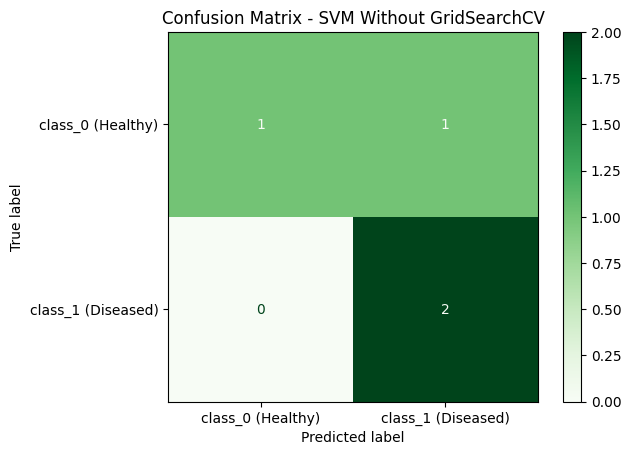

In [3]:
svm_baseline = SVC(C=0.1, kernel='rbf', random_state=42)
svm_baseline.fit(X_train_scaled, y_train)
y_pred_base = svm_baseline.predict(X_test_scaled)

base_acc = accuracy_score(y_test, y_pred_base)
print(f'Baseline SVM Accuracy: {base_acc:.4f} ({base_acc*100:.2f}%)')

print('\nClassification Report:')
print(classification_report(y_test, y_pred_base, target_names=target_names, zero_division=0))

cm_base = confusion_matrix(y_test, y_pred_base)
print('Confusion Matrix:\n', cm_base)

ConfusionMatrixDisplay(cm_base, display_labels=target_names).plot(cmap='Greens')
plt.title('Confusion Matrix - SVM Without GridSearchCV')
plt.show()

### 2c. Apply SVM with GridSearchCV & Show Confusion Matrix

Fitting 3 folds for each of 32 candidates, totalling 96 fits

Best Parameters: {'C': 1, 'gamma': 'scale', 'kernel': 'linear'}
Best Cross-Validation Accuracy: 0.7222
GridSearchCV SVM Test Accuracy: 1.0000 (100.00%)

Classification Report:
                    precision    recall  f1-score   support

 class_0 (Healthy)       1.00      1.00      1.00         2
class_1 (Diseased)       1.00      1.00      1.00         2

          accuracy                           1.00         4
         macro avg       1.00      1.00      1.00         4
      weighted avg       1.00      1.00      1.00         4

Confusion Matrix:
 [[2 0]
 [0 2]]


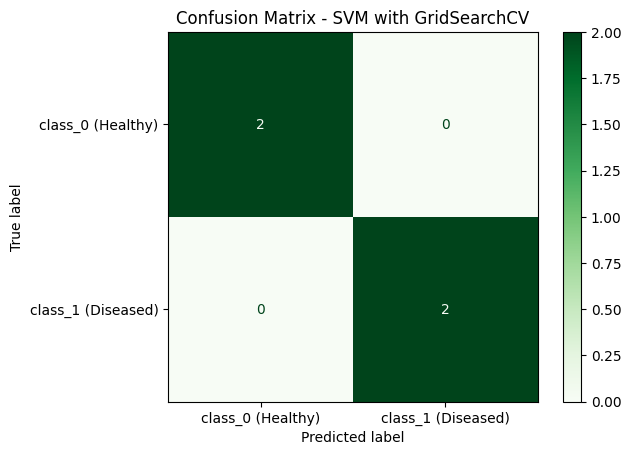

In [4]:
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.1, 1],
    'kernel': ['linear', 'rbf']
}

# Using cv=3 because the assumed training set has 8 samples (4 per class)
grid_search = GridSearchCV(SVC(random_state=42), param_grid, cv=3, verbose=1)
grid_search.fit(X_train_scaled, y_train)

print('\nBest Parameters:', grid_search.best_params_)
print(f'Best Cross-Validation Accuracy: {grid_search.best_score_:.4f}')

best_svm = grid_search.best_estimator_
y_pred_tuned = best_svm.predict(X_test_scaled)
tuned_acc = accuracy_score(y_test, y_pred_tuned)

print(f'GridSearchCV SVM Test Accuracy: {tuned_acc:.4f} ({tuned_acc*100:.2f}%)')
print('\nClassification Report:')
print(classification_report(y_test, y_pred_tuned, target_names=target_names, zero_division=0))

cm_tuned = confusion_matrix(y_test, y_pred_tuned)
print('Confusion Matrix:\n', cm_tuned)

ConfusionMatrixDisplay(cm_tuned, display_labels=target_names).plot(cmap='Greens')
plt.title('Confusion Matrix - SVM with GridSearchCV')
plt.show()

### 2d. Compare the Results of Both

                   Model  Test Accuracy  Accuracy (%)
SVM without GridSearchCV           0.75          75.0
   SVM with GridSearchCV           1.00         100.0

Baseline SVM accuracy : 75.00%
Tuned SVM accuracy    : 100.00%
Change in accuracy    : +25.00 percentage points


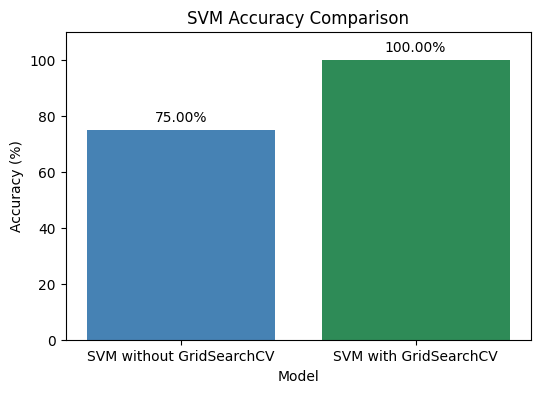

In [5]:
comparison_df = pd.DataFrame({
    'Model': ['SVM without GridSearchCV', 'SVM with GridSearchCV'],
    'Test Accuracy': [base_acc, tuned_acc],
    'Accuracy (%)': [base_acc * 100, tuned_acc * 100]
})

print(comparison_df.to_string(index=False))
print(f"\nBaseline SVM accuracy : {base_acc*100:.2f}%")
print(f"Tuned SVM accuracy    : {tuned_acc*100:.2f}%")
print(f"Change in accuracy    : +{(tuned_acc - base_acc)*100:.2f} percentage points")

plt.figure(figsize=(6, 4))
bars = plt.bar(comparison_df['Model'], comparison_df['Accuracy (%)'], color=['steelblue', 'seagreen'])
plt.ylim(0, 110)
plt.ylabel('Accuracy (%)')
plt.xlabel('Model')
plt.title('SVM Accuracy Comparison')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 2, f'{yval:.2f}%', ha='center', va='bottom')
plt.show()